# Single-subject TFA

`htfa.TFA` fits one subject: `X ≈ F(R; centers, widths) W`, where `X` is `(V, T)` data, `R` the `(V, D)` voxel coordinates, `F` a `(V, K)` matrix of radial basis factors (Gaussians with a center and a width `w = 2 sigma^2`) and `W` the `(K, T)` weights. This tutorial uses the estimator directly, rather than `htfa.fit`, to look at its options: the initialization, convergence, standardization, subsampling and an explicit starting point.

The data are 2D synthetic data (a 20 x 20 grid, 4 factors, 40 time points), so the truth is known.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

import htfa
from htfa.synthetic import match_factors
from htfa.tfa import standardize_data

htfa.set_autoinstall(False)

K = 4
X, R, truth = htfa.make_tfa_data((20, 20), n_samples=40, K=K, noise=0.1, random_state=0)
print("X:", X.shape, "R:", R.shape)
print("true centers:\n", np.round(truth["centers"], 1))
print("true widths:", np.round(truth["widths"], 1))


def errors(model):
    """Matched center error (grid units) and relative width error."""
    perm = match_factors(truth["centers"], model.centers_)
    c = np.linalg.norm(model.centers_[perm] - truth["centers"], axis=1)
    w = np.abs(model.widths_[perm] - truth["widths"]) / truth["widths"]
    return c, w

X: (400, 40) R: (400, 2)
true centers:
 [[14.3 15.8]
 [11.1 13. ]
 [10.2 16.1]
 [14.3  1.9]]
true widths: [7.  4.2 2.8 2.7]


## 1. A first fit

The data are already z-scored in the sense of the generator, so `standardize=False`. The constructor stores the options; `fit(X, coords)` returns the estimator, with fitted attributes that end in an underscore.

In [2]:
t0 = time.perf_counter()
tfa = htfa.TFA(K=K, standardize=False, random_state=0).fit(X, R)
print(f"fit time: {time.perf_counter() - t0:.1f} s")
c, w = errors(tfa)
print("center error per factor:", np.round(c, 2))
print("relative width error per factor:", np.round(w, 3))
print(
    "centers_",
    tfa.centers_.shape,
    "widths_",
    tfa.widths_.shape,
    "weights_",
    tfa.weights_.shape,
)
print("winning init_:", tfa.init_, "| n_iter_:", tfa.n_iter_, "| engine_:", tfa.engine_)
print("converged_:", tfa.converged_, "| converged_reason_:", tfa.converged_reason_)
print(f"cost_: {tfa.cost_:.3f}")
r = np.corrcoef(tfa.reconstruct().ravel(), X.ravel())[0, 1]
print(f"correlation of reconstruction with data: {r:.4f}")

fit time: 1.4 s
center error per factor: [0.01 0.01 0.03 0.02]
relative width error per factor: [0.022 0.023 0.04  0.051]
centers_ (4, 2) widths_ (4,) weights_ (4, 40)
winning init_: power | n_iter_: 12 | engine_: numpy
converged_: True | converged_reason_: threshold
cost_: 520.393
correlation of reconstruction with data: 0.9295


## 2. Initialization

`init` chooses the starting centers and widths. Each option is a K-means++ draw on the voxel coordinates:

- `'kmeans'`: unweighted, as in BrainIAK;
- `'power'`: voxels weighted by their signal power;
- `'ncorr'`: voxels weighted by the squared mean correlation with their nearest spatial neighbors;
- `'auto'` (default): all of these. Each candidate is fitted and the one with the lowest full-data objective wins. `init_objectives_` holds the objective of every candidate.

The loop below fits each option separately, then `'auto'`. The last lines of the next cell fit `'auto'` on per-voxel z-scored data (`standardize='auto'`) and print which candidates were run: `'ncorr'` and `'kmeans'`, without `'power'`, whereas all three ran with `standardize=False`.

In [3]:
fits = {}
for init in ["kmeans", "power", "ncorr", "auto"]:
    t0 = time.perf_counter()
    m = htfa.TFA(K=K, init=init, standardize=False, random_state=0).fit(X, R)
    fits[init] = m
    c, w = errors(m)
    print(
        f"init={init:6s} winner={m.init_:6s} n_iter={m.n_iter_:3d} "
        f"reason={m.converged_reason_:9s} cost={m.cost_:9.3f} "
        f"max center err={c.max():.2f} max width err={w.max():.3f} "
        f"({time.perf_counter() - t0:.1f} s)"
    )
print("\ninit_objectives_ of the 'auto' fit:")
for name, value in fits["auto"].init_objectives_.items():
    print(f"  {name:6s} {value:.3f}")

# On per-voxel z-scored data every voxel has the same power, so 'power' is skipped.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    z = htfa.TFA(K=K, init="auto", standardize="auto", random_state=0).fit(X, R)
print("\ncandidates run with standardize='auto':", list(z.init_objectives_))
print("candidates run with standardize=False :", list(fits["auto"].init_objectives_))

init=kmeans winner=kmeans n_iter= 30 reason=threshold cost=  798.823 max center err=9.70 max width err=0.683 (0.5 s)
init=power  winner=power  n_iter= 12 reason=threshold cost=  520.393 max center err=0.03 max width err=0.051 (0.2 s)


init=ncorr  winner=ncorr  n_iter= 14 reason=threshold cost=  520.405 max center err=0.03 max width err=0.051 (0.4 s)


init=auto   winner=power  n_iter= 12 reason=threshold cost=  520.393 max center err=0.03 max width err=0.051 (0.8 s)

init_objectives_ of the 'auto' fit:
  ncorr  520.405
  power  520.393
  kmeans 798.823



candidates run with standardize='auto': ['ncorr', 'kmeans']
candidates run with standardize=False : ['ncorr', 'power', 'kmeans']


On this data the `kmeans` start ended with a cost of 798.8 and the largest errors; the `power` and `ncorr` starts ended with costs of 520.4 and errors of at most 0.03 grid units in the centers. `'auto'` kept the start with the lowest objective (`power`, by 0.012 over `ncorr`); the `'auto'` run fitted all three candidates.

## 3. Convergence

Each outer iteration alternates a nonlinear least-squares update of the centers and widths with a ridge regression for the weights. The fit stops when the scaled change between iterations falls below `threshold` (`converged_reason_ == 'threshold'`) or after `max_iter` iterations (`'max_iter'`). When it stops at `max_iter` a `ConvergenceWarning` is raised. `max_iter=0` evaluates the starting point without any iteration.

In [4]:
for kwargs in [
    dict(max_iter=100, threshold=1e-3),
    dict(max_iter=100, threshold=1e-1),
    dict(max_iter=2, threshold=1e-3),
    dict(max_iter=0, threshold=1e-3),
]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        m = htfa.TFA(
            K=K, init="ncorr", standardize=False, random_state=0, **kwargs
        ).fit(X, R)
    c, w = errors(m)
    print(
        f"{kwargs}: n_iter={m.n_iter_}, converged_={m.converged_}, "
        f"reason={m.converged_reason_}, cost={m.cost_:.3f}, "
        f"max center err={c.max():.2f}, "
        f"warnings={[x.category.__name__ for x in caught]}"
    )

{'max_iter': 100, 'threshold': 0.001}: n_iter=14, converged_=True, reason=threshold, cost=520.405, max center err=0.03, warnings=[]


{'max_iter': 100, 'threshold': 0.1}: n_iter=5, converged_=True, reason=threshold, cost=524.020, max center err=0.05, warnings=[]


{'max_iter': 2, 'threshold': 0.001}: n_iter=2, converged_=False, reason=max_iter, cost=570.400, max center err=0.18, warnings=['ConvergenceWarning']
{'max_iter': 0, 'threshold': 0.001}: n_iter=0, converged_=False, reason=max_iter, cost=1097.605, max center err=1.35, warnings=[]


Loosening the threshold from 0.001 to 0.1 cut the iterations from 14 to 5, at a cost of 524.0 instead of 520.4. Limiting `max_iter` to 2 stopped before convergence and raised a `ConvergenceWarning`; `max_iter=0` returns the start itself (cost 1097.6, max center error 1.35).

## 4. Standardization

Real data have an arbitrary intensity offset and scale at every voxel, and the TFA model has no intercept. With `standardize='auto'` (the default) each voxel is z-scored over time whenever `T > 1`; `False` fits the raw values. Below, the synthetic data get a different offset and scale at every voxel (`X_raw`), as fMRI intensity differs between voxels, and each version is fitted with both settings.

Z-scoring gives every voxel unit variance, including voxels that no factor reaches, so the factors fitted to standardized data describe the standardized data, not the generating `F W`. The width errors below are measured against the generating widths and need not reach zero.

In [5]:
rng = np.random.default_rng(1)
scale = rng.uniform(5, 50, size=(X.shape[0], 1))
offset = rng.uniform(500, 1500, size=(X.shape[0], 1))
X_raw = X * scale + offset
print(
    "raw data mean / std over all entries:",
    round(X_raw.mean(), 1),
    round(X_raw.std(), 1),
)


diff = np.abs(standardize_data(X_raw, "auto") - standardize_data(X, "auto")).max()
print(f"max |standardized(X_raw) - standardized(X)|: {diff:.1e}")

for name, data in [("X", X), ("X_raw", X_raw)]:
    for std in [False, "auto"]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = htfa.TFA(K=K, standardize=std, random_state=0).fit(data, R)
        c, w = errors(m)
        print(
            f"{name:5s} standardize={std!r:7}: reason={m.converged_reason_:9s} "
            f"center err={np.round(c, 2)} width err={np.round(w, 2)}"
        )

raw data mean / std over all entries: 1019.2 291.1
max |standardized(X_raw) - standardized(X)|: 5.6e-13


X     standardize=False  : reason=threshold center err=[0.01 0.01 0.03 0.02] width err=[0.02 0.02 0.04 0.05]


X     standardize='auto' : reason=threshold center err=[0.47 0.57 0.66 0.07] width err=[2.24 1.28 1.31 2.44]
X_raw standardize=False  : reason=threshold center err=[7.87 3.84 6.63 8.96] width err=[16.19 27.56 41.5  43.57]


X_raw standardize='auto' : reason=threshold center err=[0.47 0.57 0.66 0.07] width err=[2.24 1.28 1.31 2.44]


Per-voxel z-scoring removes any per-voxel offset and scale, so `X` and `X_raw` standardize to the same array (maximum difference 5.6e-13) and both `'auto'` rows are identical. On `X_raw`, `standardize=False` gave center errors of 3.8 to 9.0 grid units and relative width errors of 16 to 44: the fit follows the intensity differences between voxels, not the factors. With `'auto'` the center errors are at most 0.66 grid units. The relative width errors are 1.3 to 2.4 because of the unit-variance rescaling described above. On the clean synthetic `X`, which is already on the generating scale, `standardize=False` gives the smaller errors in the printed lines. `'auto'` is the default: it z-scores each voxel over time when `T > 1` and leaves single-sample data unchanged.

`htfa.tfa.standardize_data` applies the same transform to an array, and `reconstruct()` returns values in the standardized space.

## 5. Subsampling

For large data, each iteration can update the centers and widths from a random subset of voxels and time points: `voxel_ratio` and `tr_ratio` give fractions, `max_voxels` and `max_trs` give caps (the data are never oversampled). The weights are always fitted on the full data. A new subset is drawn every iteration, so the change between iterations does not settle as it does with all the data. The fit therefore also evaluates the full-data objective after every iteration and stops (`'objective'`) when it falls by less than a relative 1e-4, or on a `'plateau'` when the change has not reached a new minimum for 5 consecutive iterations.

In [6]:
for kwargs in [
    dict(),
    dict(voxel_ratio=0.5),
    dict(voxel_ratio=0.5, tr_ratio=0.5),
    dict(max_voxels=100, max_trs=20),
]:
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = htfa.TFA(
            K=K, init="ncorr", standardize=False, random_state=0, **kwargs
        ).fit(X, R)
    c, w = errors(m)
    print(
        f"{str(kwargs):38s} n_iter={m.n_iter_:3d} reason={m.converged_reason_:9s} "
        f"max center err={c.max():.2f} max width err={w.max():.3f} "
        f"({time.perf_counter() - t0:.1f} s)"
    )

{}                                     n_iter= 14 reason=threshold max center err=0.03 max width err=0.051 (0.2 s)


{'voxel_ratio': 0.5}                   n_iter= 13 reason=objective max center err=0.11 max width err=0.102 (0.3 s)
{'voxel_ratio': 0.5, 'tr_ratio': 0.5}  n_iter= 13 reason=objective max center err=0.08 max width err=0.074 (0.1 s)
{'max_voxels': 100, 'max_trs': 20}     n_iter= 12 reason=objective max center err=0.26 max width err=0.109 (0.1 s)


With `voxel_ratio=0.5` and with the caps, the fits stopped on the objective rule (see the printed reasons), and their center and width errors can be compared with the full-data fit's in the printed lines above. The weights `weights_` are fitted on all data in every case.

## 6. An explicit starting point

`fit(X, R, start=(centers, widths))` skips the initialization. The start is used as given; here it is the true centers and widths, then the true values displaced by a few grid units. `max_iter=0` reports how good the start is before any iteration.

In [7]:
rng = np.random.default_rng(2)
true_start = (truth["centers"], truth["widths"])
bad_start = (
    truth["centers"] + rng.normal(0, 3, truth["centers"].shape),
    truth["widths"] * 1.5,
)

for name, start in [("true values", true_start), ("displaced values", bad_start)]:
    m0 = htfa.TFA(K=K, max_iter=0, standardize=False, random_state=0).fit(
        X, R, start=start
    )
    m = htfa.TFA(K=K, standardize=False, random_state=0).fit(X, R, start=start)
    c0, _ = errors(m0)
    c, w = errors(m)
    print(
        f"{name:17s}: start center err max {c0.max():.2f}, cost {m0.cost_:.3f} -> "
        f"after fit: n_iter={m.n_iter_}, max center err {c.max():.2f}, "
        f"max width err {w.max():.3f}, cost {m.cost_:.3f}"
    )

true values      : start center err max 0.00, cost 520.292 -> after fit: n_iter=7, max center err 0.03, max width err 0.051, cost 520.376
displaced values : start center err max 7.43, cost 1874.903 -> after fit: n_iter=36, max center err 7.45, max width err 0.635, cost 798.728


From the true values the fit moved the centers by at most the printed distance. The displaced start ended in a different solution, whose cost is close to the `kmeans` fit in section 2, so a poor start can end in a poor local solution. This is the reason `init='auto'` compares several starts.

## 7. Looking at the factors

`TFA.factors()` returns the `(V, K)` factor matrix at the training coordinates (or at any coordinates passed in). For 2D data the factors can be shown as images.

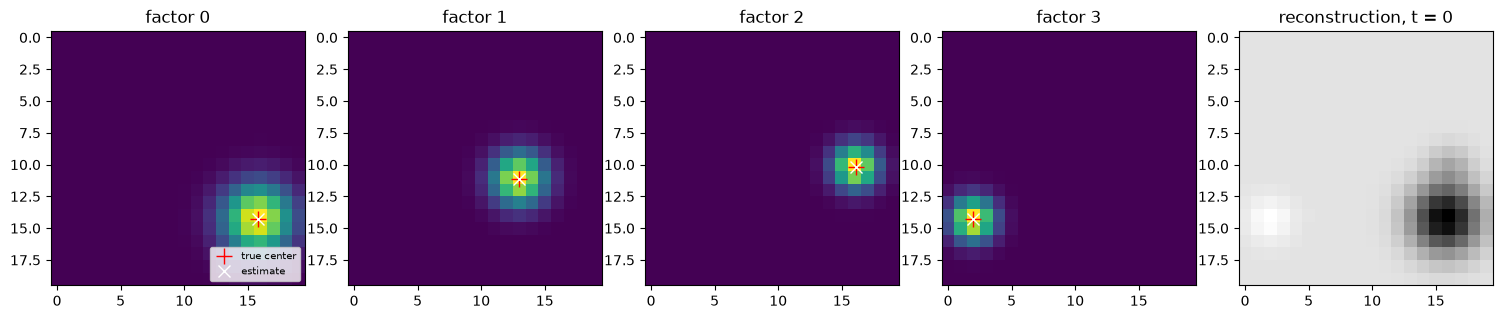

In [8]:
F = tfa.factors()
c, _ = errors(tfa)
perm = match_factors(truth["centers"], tfa.centers_)
fig, axes = plt.subplots(1, K + 1, figsize=(3 * (K + 1), 3))
for k, ax in enumerate(axes[:K]):
    ax.imshow(F[:, perm[k]].reshape(20, 20), cmap="viridis")
    ax.plot(
        truth["centers"][k, 1], truth["centers"][k, 0], "r+", ms=12, label="true center"
    )
    ax.plot(
        tfa.centers_[perm[k], 1], tfa.centers_[perm[k], 0], "wx", ms=8, label="estimate"
    )
    ax.set_title(f"factor {k}")
axes[0].legend(loc="lower right", fontsize=7)
axes[K].imshow(tfa.reconstruct()[:, 0].reshape(20, 20), cmap="gray")
axes[K].set_title("reconstruction, t = 0")
fig.tight_layout()
plt.show()